# HW3: Hyperparameter Tuning — Chest X-ray (NORMAL vs PNEUMONIA)
**115061534 江承瀚** · Deep Learning in Biomedical Optical Imaging (11510IPT 553000)

This notebook extends the provided starter code. It is organized to follow the analysis report:

0. Setup — libraries, data cache, generic `run()` experiment driver
1. Data & baseline analysis
2. Optimization settings (learning rate, batch size, optimizer)
3. Training schedule & regularization (LR scheduler, epochs, weight decay)
4. Model architecture (depth, width, dropout, normalization, CNN)
5. Data augmentation (manual + automatic policies)
6. Conclusion — summary table, final model (3 seeds)

**Run environment.** Everything was run locally on CPU (16 cores, PyTorch 2.11). Each experiment writes
`results/<name>.json` (+ best checkpoint in `ckpt/`); re-running the notebook re-uses finished experiments
and only re-draws tables / figures, so delete `results/` to re-train from scratch. To save wall-clock time on CPU,
the Section-5 runs were trained in a second process (`aug_worker.py`, same code) in parallel with this notebook.
Set `DATA_ROOT` to the folder that contains `train/ val/ test/`.

**Changes to the starter code (and why).**
* The starter created `lr_scheduler` *before* `optimizer` (→ `NameError`); fixed by building the scheduler after the optimizer.
* Accuracy is computed over the whole set, not as the mean of per-batch accuracies (the last, smaller batch was over-weighted).
* The official validation set has only 16 images (one image = 6.25 % accuracy). For model selection I hold out a
  **patient-grouped 15 % split of the training set** (Section 1 explains why). The 16-image set is still reported.
* Images are decoded and resized (256×256, bicubic, grayscale — same as the starter) once and cached as `uint8` tensors.

## 0. Setup

In [1]:
import json, os, re, time, random, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optims
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from torchvision.transforms import v2
from torchvision.transforms.functional import InterpolationMode
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.model_selection import GroupShuffleSplit

DATA_ROOT = Path('chest_xray')
RES_DIR, FIG_DIR, CKPT_DIR, CACHE = Path('results'), Path('figs'), Path('ckpt'), Path('cache')
for d in (RES_DIR, FIG_DIR, CKPT_DIR, CACHE): d.mkdir(exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(8, os.cpu_count()))
print('device:', device, '| torch', torch.__version__, '| threads', torch.get_num_threads())

device: cpu | torch 2.11.0+cpu | threads 8


### Data cache
Same preprocessing as the starter (`Resize(256,256, bicubic)` → `Grayscale` ), stored as `uint8` so that
augmentations (incl. AutoAugment / RandAugment, which need `uint8`) can run on tensors.

In [2]:
pre = transforms.Compose([transforms.Resize((256, 256), interpolation=InterpolationMode.BICUBIC),
                          transforms.Grayscale(num_output_channels=1), transforms.PILToTensor()])

def load_split(split):
    f = CACHE / f'{split}_256.pt'
    if f.exists():
        return torch.load(f)
    ds = datasets.ImageFolder(DATA_ROOT / split, transform=pre)
    x = torch.stack([ds[i][0] for i in range(len(ds))])                # uint8 [N,1,256,256]
    y = torch.tensor(ds.targets)
    names = [Path(p).name for p, _ in ds.samples]
    out = dict(x=x, y=y, names=names, classes=ds.classes)
    torch.save(out, f)
    return out

data = {s: load_split(s) for s in ('train', 'val', 'test')}
CLASSES = data['train']['classes']
print(CLASSES, {s: tuple(d['x'].shape) for s, d in data.items()})

['NORMAL', 'PNEUMONIA'] {'train': (2000, 1, 256, 256), 'val': (16, 1, 256, 256), 'test': (624, 1, 256, 256)}


### Patient-grouped validation split
File names encode the patient (`person1946_bacteria_4874.jpeg`, `IM-0115-0001.jpeg`, `NORMAL2-IM-0341-0001.jpeg`).
Several images can come from the same patient, so a random image-level split would leak patients between
training and validation. I split **by patient, stratified by class** (15 % of the patients of each class).

In [3]:
def patient_id(name):
    if name.startswith('person'):
        return name.split('_')[0]                       # person1946
    m = re.match(r'(NORMAL2-)?IM-(\d+)', name)
    return (m.group(1) or 'N1-') + m.group(2)

groups = np.array([patient_id(n) for n in data['train']['names']])
ytr = data['train']['y'].numpy()
tr_idx, va_idx = [], []
for c in (0, 1):
    idx = np.where(ytr == c)[0]
    a, b = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=0).split(idx, groups=groups[idx]))
    tr_idx += list(idx[a]); va_idx += list(idx[b])
tr_idx, va_idx = np.array(sorted(tr_idx)), np.array(sorted(va_idx))
assert not set(groups[tr_idx]) & set(groups[va_idx])
print(f'train-split {len(tr_idx)} imgs | val-split {len(va_idx)} imgs | '
      f'val-split class counts {np.bincount(ytr[va_idx])}')

train-split 1703 imgs | val-split 297 imgs | val-split class counts [158 139]


### Datasets, models, experiment driver

In [4]:
class TensorDS(Dataset):
    """uint8 image tensors -> (optional uint8 augmentation) -> float in [0,1]."""
    def __init__(self, x, y, tf=None):
        self.x, self.y, self.tf = x, y, tf
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        img = self.x[i]
        if self.tf is not None:
            img = self.tf(img)
        return img.float() / 255., self.y[i]

def make_sets(val='split', aug=None):
    tr = data['train']
    if val == 'split':
        train = TensorDS(tr['x'][tr_idx], tr['y'][tr_idx], aug)
        valid = TensorDS(tr['x'][va_idx], tr['y'][va_idx])
    else:                                               # starter setting: all 2000 train imgs, 16-img val
        train = TensorDS(tr['x'], tr['y'], aug)
        valid = TensorDS(data['val']['x'], data['val']['y'])
    return train, valid

val16_ds = TensorDS(data['val']['x'], data['val']['y'])
test_ds = TensorDS(data['test']['x'], data['test']['y'])

def mlp(width=64, depth=3, dropout=0.5, bn=True):
    """Starter MLP (width=64, depth=3, dropout=0.5, bn=True) with configurable size."""
    layers, d_in = [nn.Flatten()], 256 * 256
    for _ in range(depth):
        layers += [nn.Linear(d_in, width)] + ([nn.BatchNorm1d(width)] if bn else []) + [nn.ReLU()]
        layers += [nn.Dropout(dropout)] if dropout > 0 else []
        d_in = width
    return nn.Sequential(*layers, nn.Linear(d_in, 1), nn.Sigmoid())

def cnn(ch=(16, 32, 64, 128, 128), dropout=0.3, bn=True):
    """Small VGG-style CNN: stride-2 stem (256->128) then conv-BN-ReLU-maxpool blocks, global average pooling."""
    norm = (lambda c: nn.BatchNorm2d(c)) if bn else (lambda c: nn.Identity())
    layers = [nn.Conv2d(1, ch[0], 5, stride=2, padding=2, bias=not bn), norm(ch[0]), nn.ReLU(), nn.MaxPool2d(2)]
    for a, b in zip(ch[:-1], ch[1:]):
        layers += [nn.Conv2d(a, b, 3, padding=1, bias=not bn), norm(b), nn.ReLU(), nn.MaxPool2d(2)]
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout),
                         nn.Linear(ch[-1], 1), nn.Sigmoid())

ARCH = {'mlp': mlp, 'cnn': cnn}

def make_opt(params, opt, lr, wd):
    if opt == 'sgd':   return optims.SGD(params, lr=lr, weight_decay=wd)
    if opt == 'sgdm':  return optims.SGD(params, lr=lr, momentum=0.9, weight_decay=wd)
    if opt == 'adam':  return optims.Adam(params, lr=lr, weight_decay=wd)
    if opt == 'adamw': return optims.AdamW(params, lr=lr, weight_decay=wd)
    raise ValueError(opt)

def make_sched(o, sched, epochs):
    if sched == 'plateau': return optims.lr_scheduler.ReduceLROnPlateau(o, factor=0.1, patience=5, mode='max')
    if sched == 'step':    return optims.lr_scheduler.StepLR(o, step_size=max(1, epochs // 3), gamma=0.1)
    if sched == 'cosine':  return optims.lr_scheduler.CosineAnnealingLR(o, T_max=epochs)
    return None

@torch.no_grad()
def predict(model, ds, bs=128):
    model.eval()
    probs, ys = [], []
    for x, y in DataLoader(ds, batch_size=bs):
        probs.append(model(x.to(device)).view(-1).cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def metrics(p, y, thr=0.5):
    pc = np.clip(p, 1e-7, 1 - 1e-7)
    pred = (p > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(loss=float(-np.mean(y * np.log(pc) + (1 - y) * np.log(1 - pc))),
                acc=100 * float((pred == y).mean()),
                sens=100 * tp / (tp + fn), spec=100 * tn / (tn + fp),
                f1=100 * 2 * tp / (2 * tp + fp + fn), auc=100 * float(roc_auc_score(y, p)),
                cm=[[int(tn), int(fp)], [int(fn), int(tp)]])

DEFAULT = dict(arch='mlp', arch_kw={}, opt='adam', lr=1e-3, wd=1e-3, bs=64, epochs=10,
               sched='plateau', aug=None, val='split', seed=0)

def run(name, aug_tf=None, verbose=False, **cfg):
    """Train one configuration (DEFAULT updated by cfg); cache history + test metrics in results/<name>.json."""
    f = RES_DIR / f'{name}.json'
    if f.exists():
        return report(json.loads(f.read_text()), verbose)
    c = {**DEFAULT, **cfg}
    random.seed(c['seed']); np.random.seed(c['seed']); torch.manual_seed(c['seed'])
    train_ds, val_ds = make_sets(c['val'], aug_tf)
    loader = DataLoader(train_ds, batch_size=c['bs'], shuffle=True, generator=torch.Generator().manual_seed(c['seed']))
    model = ARCH[c['arch']](**c['arch_kw']).to(device)
    o = make_opt(model.parameters(), c['opt'], c['lr'], c['wd'])
    s = make_sched(o, c['sched'], c['epochs'])
    crit = nn.BCELoss()
    hist = {k: [] for k in ('train_loss', 'train_acc', 'val_loss', 'val_acc', 'lr', 'time')}
    best, best_state, best_ep = (-1, 0), None, 0
    for ep in range(c['epochs']):
        t0 = time.time(); model.train(); tl, tc, n = 0., 0, 0
        for x, y in loader:
            x, y = x.to(device), y.to(device).float()
            o.zero_grad()
            p = model(x).view(-1)
            loss = crit(p, y)
            loss.backward(); o.step()
            tl += loss.item() * len(y); tc += ((p > 0.5).float() == y).sum().item(); n += len(y)
        vm = metrics(*predict(model, val_ds))
        for k, v in zip(hist, (tl / n, 100 * tc / n, vm['loss'], vm['acc'], o.param_groups[0]['lr'], time.time() - t0)):
            hist[k].append(v)
        if (vm['acc'], -vm['loss']) > best:              # best val acc, ties -> lower val loss
            best, best_state, best_ep = (vm['acc'], -vm['loss']), copy.deepcopy(model.state_dict()), ep
        if isinstance(s, optims.lr_scheduler.ReduceLROnPlateau): s.step(vm['acc'])
        elif s is not None: s.step()
    torch.save(best_state, CKPT_DIR / f'{name}.pth')
    model.load_state_dict(best_state)
    pv, yv = predict(model, val_ds); pt, yt = predict(model, test_ds); p16, y16 = predict(model, val16_ds)
    res = dict(name=name, cfg={k: v for k, v in c.items()}, hist=hist, best_epoch=best_ep + 1,
               val=metrics(pv, yv), val16=metrics(p16, y16), test=metrics(pt, yt),
               n_params=sum(p.numel() for p in model.parameters()), sec_per_epoch=float(np.mean(hist['time'])))
    f.write_text(json.dumps(res))
    return report(res, verbose)

def report(res, verbose):
    """Print the per-epoch log (verbose) and a one-line summary of a run (freshly trained or loaded from cache)."""
    h = res['hist']
    if verbose:
        for ep in range(len(h['train_loss'])):
            print(f"Epoch {ep+1}/{len(h['train_loss'])} - loss: {h['train_loss'][ep]:.4f} - train_acc: {h['train_acc'][ep]:.2f}% "
                  f"- val_loss: {h['val_loss'][ep]:.4f} - val_acc: {h['val_acc'][ep]:.2f}% - time: {h['time'][ep]:.1f}s")
    print(f"[{res['name']}] best ep {res['best_epoch']} | val acc {res['val']['acc']:.2f} | test acc {res['test']['acc']:.2f} "
          f"auc {res['test']['auc']:.2f} | {res['sec_per_epoch']:.1f}s/ep")
    return res

def table(names):
    rows = []
    for n in names:
        r = json.loads((RES_DIR / f'{n}.json').read_text())
        h = r['hist']
        rows.append(dict(run=n, best_ep=r['best_epoch'], train_acc=h['train_acc'][-1], val_acc=r['val']['acc'],
                         gap=h['train_acc'][-1] - h['val_acc'][-1], val_loss=r['val']['loss'],
                         test_acc=r['test']['acc'], test_sens=r['test']['sens'], test_spec=r['test']['spec'],
                         test_auc=r['test']['auc'], params=r['n_params'], s_per_ep=r['sec_per_epoch']))
    df = pd.DataFrame(rows).set_index('run')
    return df.round(2).assign(val_loss=df['val_loss'].round(4))   # 4 decimals: val_loss is the selection tie-breaker

def plot_runs(names, title, fname, labels=None):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for i, n in enumerate(names):
        h = json.loads((RES_DIR / f'{n}.json').read_text())['hist']
        c, lab, ep = f'C{i}', (labels[i] if labels else n), range(1, len(h['train_loss']) + 1)
        ax[0].plot(ep, h['train_loss'], c=c, label=lab); ax[0].plot(ep, h['val_loss'], c=c, ls='--')
        ax[1].plot(ep, h['train_acc'], c=c, label=lab); ax[1].plot(ep, h['val_acc'], c=c, ls='--')
        ax[2].plot(ep, h['lr'], c=c, label=lab)
    ax[0].set(title='Loss (solid: train, dashed: val)', xlabel='epoch', ylabel='BCE')
    ax[0].set_ylim(0, min(2, ax[0].get_ylim()[1]))
    ax[1].set(title='Accuracy (solid: train, dashed: val)', xlabel='epoch', ylabel='%')
    ax[2].set(title='Learning rate', xlabel='epoch', yscale='log')
    ax[1].legend(fontsize=8)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=130); plt.show()

## 1. Data & Baseline Analysis
### 1.1 Class distribution and split

,NORMAL,PNEUMONIA,total,% PNEUMONIA
train,1000.0,1000.0,2000.0,50.0
val,8.0,8.0,16.0,50.0
test,234.0,390.0,624.0,62.5
train-split (ours),842.0,861.0,1703.0,50.6
val-split (ours),158.0,139.0,297.0,46.8


,bacteria,normal,virus
test,242,234,148
train,708,1000,292


patients: {'train': 1201, 'val': 15, 'test': 427} | shared IDs train∩test 127 | train∩val 0
train images per patient: mean 1.67, max 30


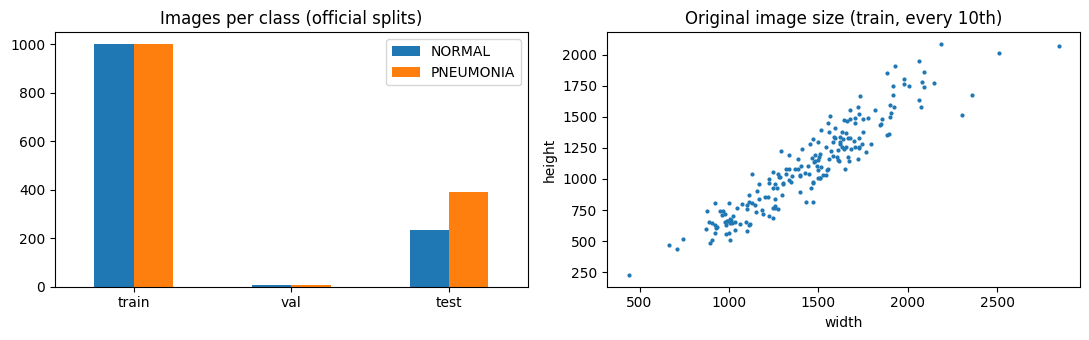

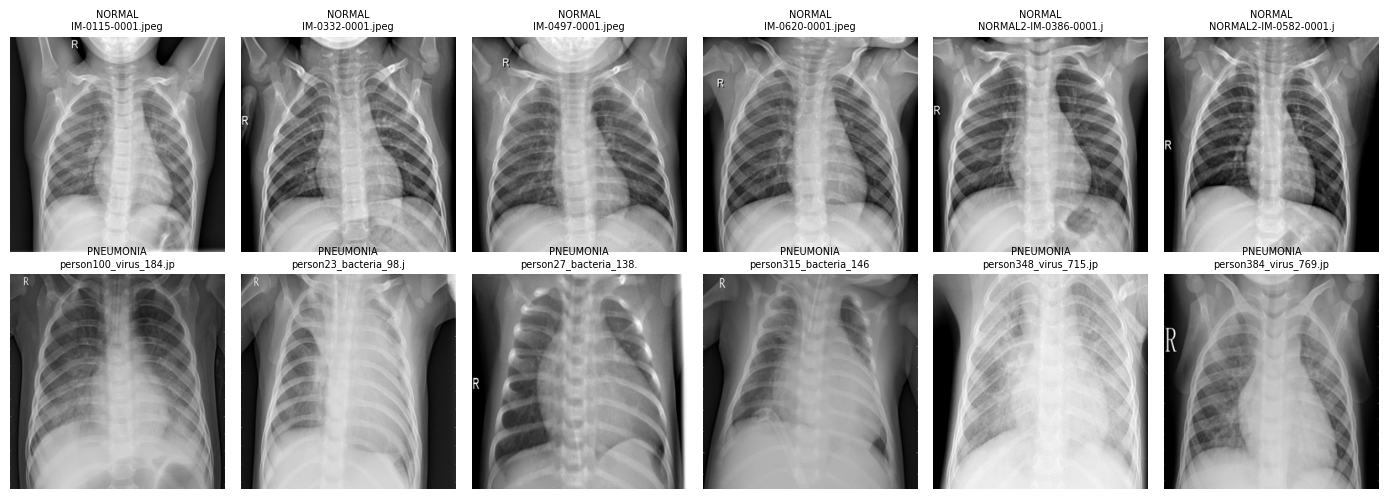

In [5]:
counts = pd.DataFrame({s: np.bincount(d['y'].numpy(), minlength=2) for s, d in data.items()}, index=CLASSES).T
counts['total'] = counts.sum(1); counts['% PNEUMONIA'] = (100 * counts['PNEUMONIA'] / counts['total']).round(1)
counts.loc['train-split (ours)'] = [*np.bincount(ytr[tr_idx]), len(tr_idx), round(100 * ytr[tr_idx].mean(), 1)]
counts.loc['val-split (ours)'] = [*np.bincount(ytr[va_idx]), len(va_idx), round(100 * ytr[va_idx].mean(), 1)]
display(counts)

pneu_kind = pd.Series([('bacteria' if 'bacteria' in n else 'virus' if 'virus' in n else 'normal')
                       for s in ('train', 'test') for n in data[s]['names']],
                      index=[s for s in ('train', 'test') for _ in data[s]['names']])
display(pneu_kind.groupby(level=0).value_counts().unstack())

pat = {s: set(patient_id(n) for n in data[s]['names']) for s in data}
print('patients:', {s: len(v) for s, v in pat.items()},
      '| shared IDs train∩test', len(pat['train'] & pat['test']), '| train∩val', len(pat['train'] & pat['val']))
# Note: patient numbers restart in each official split (e.g. test person1 is 'virus', train person1 is 'bacteria'),
# so shared IDs between train and test are not evidence of leakage; inside train they do identify the same patient.
imgs_per_patient = pd.Series(groups).value_counts()
print('train images per patient: mean %.2f, max %d' % (imgs_per_patient.mean(), imgs_per_patient.max()))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
counts.iloc[:3][CLASSES].plot.bar(ax=ax[0], rot=0, title='Images per class (official splits)')
raw_sizes = [datasets.folder.default_loader(p).size for p, _ in datasets.ImageFolder(DATA_ROOT / 'train').samples[::10]]
ax[1].scatter(*zip(*raw_sizes), s=4); ax[1].set(title='Original image size (train, every 10th)', xlabel='width', ylabel='height')
fig.tight_layout(); fig.savefig(FIG_DIR / 's1_class_dist.png', dpi=130); plt.show()

fig, ax = plt.subplots(2, 6, figsize=(14, 5))
for r, c in enumerate((0, 1)):
    for j, i in enumerate(np.where(ytr == c)[0][::150][:6]):
        ax[r, j].imshow(data['train']['x'][i, 0], cmap='gray'); ax[r, j].axis('off')
        ax[r, j].set_title(f"{CLASSES[c]}\n{data['train']['names'][i][:22]}", fontsize=7)
fig.tight_layout(); fig.savefig(FIG_DIR / 's1_samples.png', dpi=130); plt.show()

### 1.2 Baseline (starter configuration)
Starter MLP, Adam lr=1e-3, weight decay 1e-3, batch 64, ReduceLROnPlateau, 10 epochs.
* `baseline_val16`: exactly the starter protocol — train on all 2000 images, select the checkpoint on the official 16-image val set.
* `baseline_s{0,1,2}`: same model, but trained on the train-split and selected on the patient-grouped val-split (≈300 images), 3 seeds.
  This is the reference for every later experiment, and the seed spread tells how large a difference must be to be meaningful.

Epoch 1/10 - loss: 0.5382 - train_acc: 74.35% - val_loss: 0.5395 - val_acc: 75.00% - time: 5.5s
Epoch 2/10 - loss: 0.3475 - train_acc: 88.60% - val_loss: 0.4500 - val_acc: 81.25% - time: 5.3s
Epoch 3/10 - loss: 0.2387 - train_acc: 92.75% - val_loss: 0.3617 - val_acc: 93.75% - time: 5.2s
Epoch 4/10 - loss: 0.1829 - train_acc: 94.25% - val_loss: 0.2890 - val_acc: 81.25% - time: 5.1s
Epoch 5/10 - loss: 0.1543 - train_acc: 94.95% - val_loss: 0.8485 - val_acc: 68.75% - time: 4.9s
Epoch 6/10 - loss: 0.1319 - train_acc: 95.55% - val_loss: 0.9955 - val_acc: 50.00% - time: 5.1s
Epoch 7/10 - loss: 0.1225 - train_acc: 96.10% - val_loss: 0.9465 - val_acc: 62.50% - time: 4.7s
Epoch 8/10 - loss: 0.1163 - train_acc: 96.30% - val_loss: 1.0713 - val_acc: 50.00% - time: 4.8s
Epoch 9/10 - loss: 0.1054 - train_acc: 96.70% - val_loss: 0.6982 - val_acc: 68.75% - time: 4.6s
Epoch 10/10 - loss: 0.0822 - train_acc: 97.35% - val_loss: 0.1965 - val_acc: 93.75% - time: 5.3s
[baseline_val16] best ep 10 | val acc 9

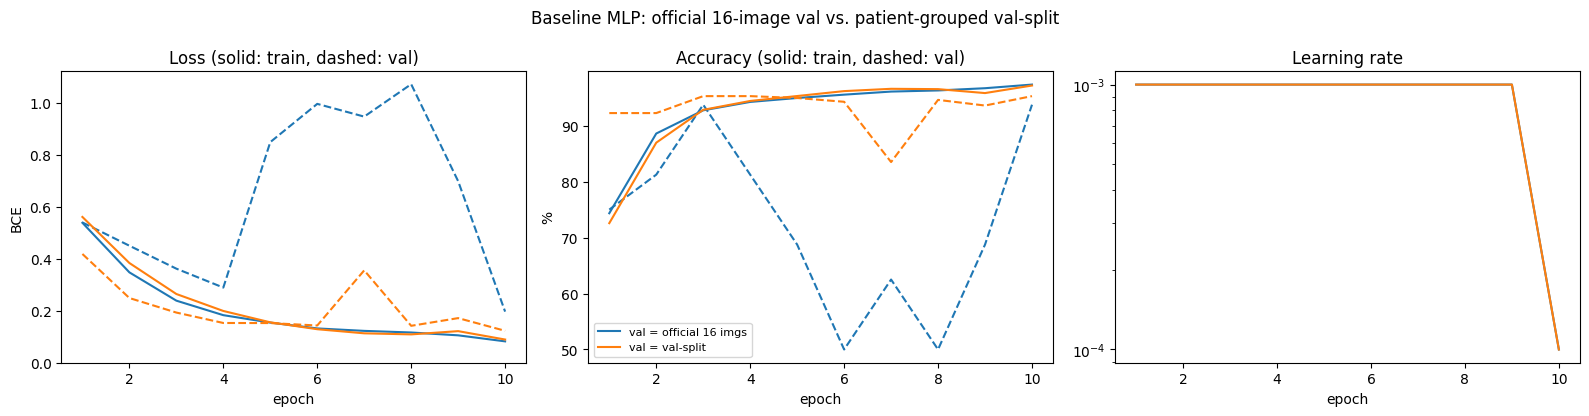

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
baseline_val16,10,97.35,93.75,3.60,0.1965,81.89,96.67,57.26,92.19,4203137,5.04
baseline_s0,10,97.18,95.29,1.90,0.1228,80.77,95.64,55.98,90.92,4203137,4.55
baseline_s1,10,96.65,95.62,1.03,0.1402,83.49,90.51,71.79,91.05,4203137,4.54
baseline_s2,10,96.30,95.29,1.01,0.1424,77.24,96.41,45.30,88.47,4203137,4.68


In [6]:
run('baseline_val16', val='official', verbose=True)
for s in range(3):
    run(f'baseline_s{s}', seed=s, verbose=(s == 0))
plot_runs(['baseline_val16', 'baseline_s0'], 'Baseline MLP: official 16-image val vs. patient-grouped val-split',
          's1_baseline.png', labels=['val = official 16 imgs', 'val = val-split'])
display(table(['baseline_val16', 'baseline_s0', 'baseline_s1', 'baseline_s2']))

In [7]:
r = json.loads((RES_DIR / 'baseline_s0.json').read_text())
print('baseline_s0 test confusion matrix [[TN, FP], [FN, TP]]:', r['test']['cm'])
v16 = np.array(json.loads((RES_DIR / 'baseline_val16.json').read_text())['hist']['val_acc'])
print('official-val accuracy per epoch:', v16.round(1), '| distinct values:', sorted(set(v16.round(2))))
# Binomial standard error of an accuracy estimate p from n images: sqrt(p(1-p)/n)
for n in (16, len(va_idx), 624):
    print(f'n={n:4d}: std. error of a 85% accuracy estimate = {100*np.sqrt(.85*.15/n):.1f} pp')

baseline_s0 test confusion matrix [[TN, FP], [FN, TP]]: [[131, 103], [17, 373]]
official-val accuracy per epoch: [75.  81.2 93.8 81.2 68.8 50.  62.5 50.  68.8 93.8] | distinct values: [50.0, 62.5, 68.75, 75.0, 81.25, 93.75]
n=  16: std. error of a 85% accuracy estimate = 8.9 pp
n= 297: std. error of a 85% accuracy estimate = 2.1 pp
n= 624: std. error of a 85% accuracy estimate = 1.4 pp


## 2. Optimization Settings
All runs: starter MLP, 10 epochs, weight decay 1e-3, ReduceLROnPlateau, val-split, seed 0. One factor changed at a time.
### 2.1 Learning rate (Adam, batch 64)

[lr_0.0001] best ep 8 | val acc 96.30 | test acc 80.77 auc 91.34 | 4.5s/ep
[lr_0.001] best ep 10 | val acc 95.29 | test acc 80.77 auc 90.92 | 4.4s/ep
[lr_0.01] best ep 4 | val acc 93.60 | test acc 80.93 auc 90.55 | 4.5s/ep


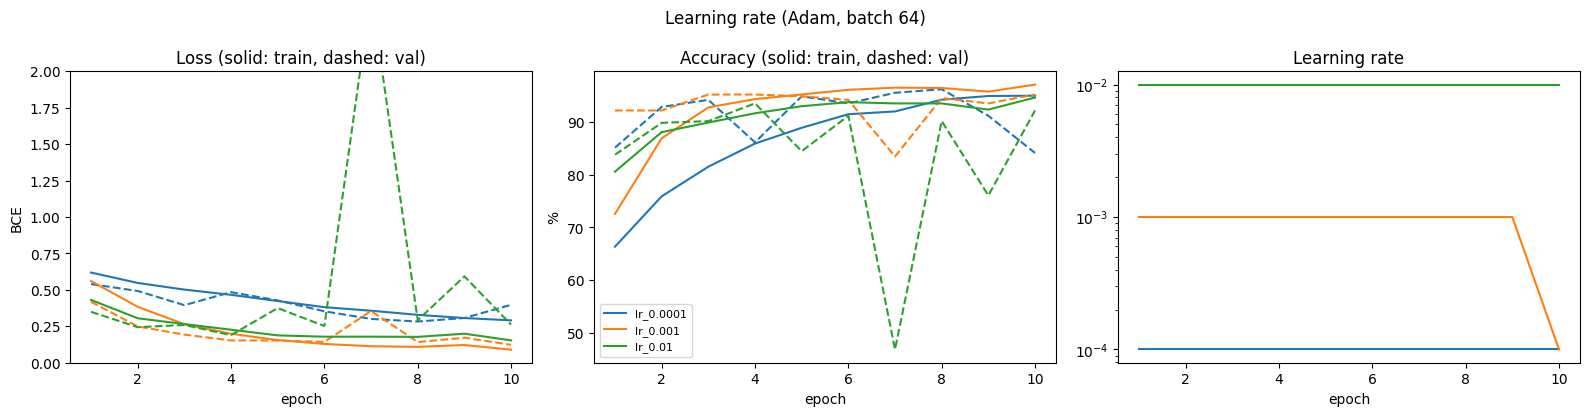

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
lr_0.0001,8,95.07,96.30,10.89,0.2828,80.77,94.62,57.69,91.34,4203137,4.49
lr_0.001,10,97.18,95.29,1.90,0.1228,80.77,95.64,55.98,90.92,4203137,4.38
lr_0.01,4,94.72,93.60,2.46,0.1895,80.93,89.23,67.09,90.55,4203137,4.51


In [8]:
LRS = [1e-4, 1e-3, 1e-2]
for lr in LRS: run(f'lr_{lr:g}', lr=lr)
plot_runs([f'lr_{lr:g}' for lr in LRS], 'Learning rate (Adam, batch 64)', 's2_lr.png')
display(table([f'lr_{lr:g}' for lr in LRS]))

### 2.2 Batch size (Adam, lr 1e-3)

[bs_16] best ep 10 | val acc 95.62 | test acc 83.01 auc 92.05 | 9.7s/ep
[bs_64] best ep 10 | val acc 95.29 | test acc 80.77 auc 90.92 | 5.9s/ep
[bs_256] best ep 10 | val acc 95.62 | test acc 82.53 auc 92.78 | 4.1s/ep


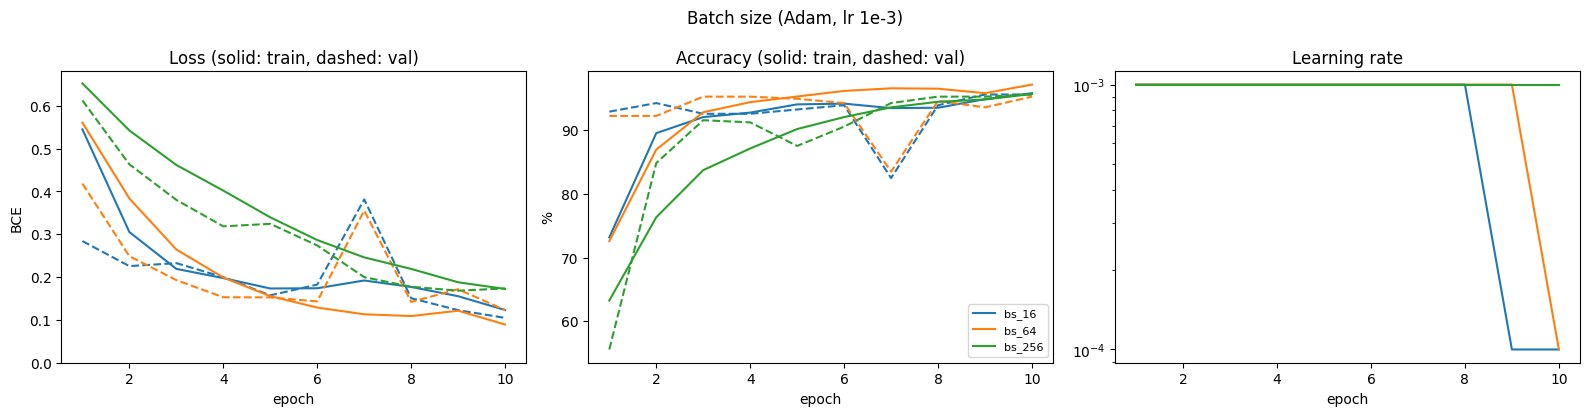

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
bs_16,10,95.83,95.62,0.21,0.1046,83.01,94.87,63.25,92.05,4203137,9.72
bs_64,10,97.18,95.29,1.90,0.1228,80.77,95.64,55.98,90.92,4203137,5.93
bs_256,10,95.71,95.62,0.09,0.1735,82.53,93.08,64.96,92.78,4203137,4.12


In [9]:
BSS = [16, 64, 256]
for bs in BSS: run(f'bs_{bs}', bs=bs)
plot_runs([f'bs_{bs}' for bs in BSS], 'Batch size (Adam, lr 1e-3)', 's2_bs.png')
display(table([f'bs_{bs}' for bs in BSS]))

### 2.3 Optimizer
SGD variants need a larger step than Adam, so they use lr = 1e-2 (Adam-family: 1e-3). AdamW uses decoupled weight decay 1e-2.

[opt_sgd] best ep 10 | val acc 95.62 | test acc 79.17 auc 91.31 | 3.3s/ep
[opt_sgdm] best ep 10 | val acc 95.62 | test acc 81.89 auc 91.80 | 3.6s/ep
[opt_adam] best ep 10 | val acc 95.29 | test acc 80.77 auc 90.92 | 4.1s/ep
[opt_adamw] best ep 5 | val acc 95.96 | test acc 82.53 auc 91.96 | 3.9s/ep


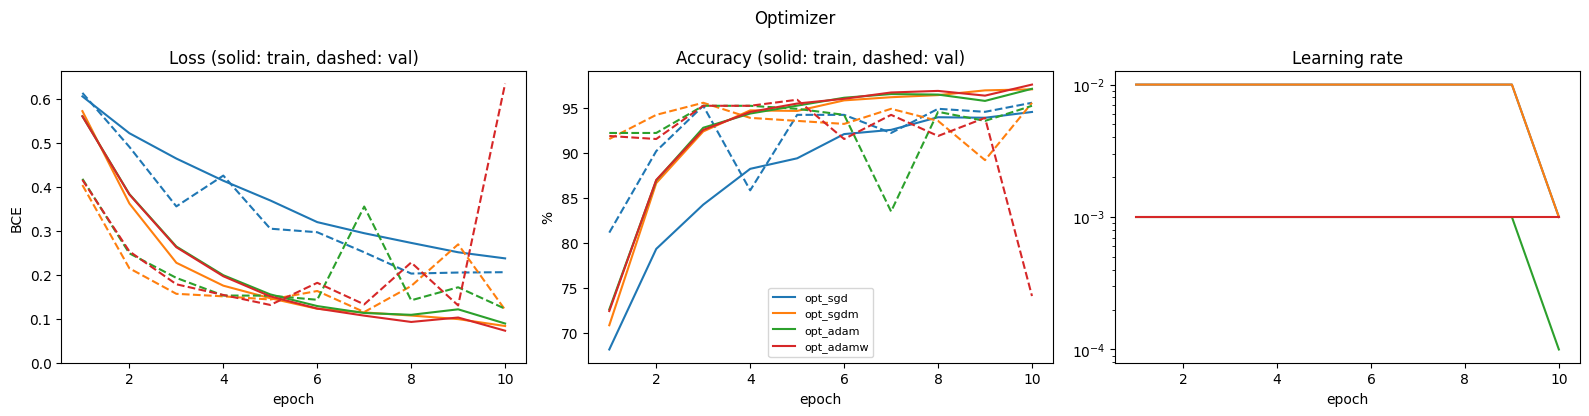

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
opt_sgd,10,94.60,95.62,-1.03,0.2059,79.17,96.41,50.43,91.31,4203137,3.32
opt_sgdm,10,97.12,95.62,1.50,0.1203,81.89,95.90,58.55,91.80,4203137,3.57
opt_adam,10,97.18,95.29,1.90,0.1228,80.77,95.64,55.98,90.92,4203137,4.08
opt_adamw,5,97.65,95.96,23.58,0.1314,82.53,95.13,61.54,91.96,4203137,3.95


In [10]:
OPTS = dict(opt_sgd=dict(opt='sgd', lr=1e-2), opt_sgdm=dict(opt='sgdm', lr=1e-2),
            opt_adam=dict(opt='adam', lr=1e-3), opt_adamw=dict(opt='adamw', lr=1e-3, wd=1e-2))
for n, kw in OPTS.items(): run(n, **kw)
plot_runs(list(OPTS), 'Optimizer', 's2_opt.png')
display(table(list(OPTS)))

## 3. Training Schedule & Regularization
Starter MLP, Adam lr 1e-3, batch 64, val-split, seed 0.
### 3.1 LR scheduler (30 epochs)

[sched_none] best ep 29 | val acc 95.62 | test acc 84.62 auc 92.92 | 4.0s/ep
[sched_step] best ep 23 | val acc 96.30 | test acc 82.21 auc 91.17 | 4.2s/ep
[sched_cosine] best ep 30 | val acc 95.62 | test acc 81.09 auc 90.90 | 4.9s/ep
[sched_plateau] best ep 23 | val acc 95.62 | test acc 81.25 auc 91.10 | 6.5s/ep


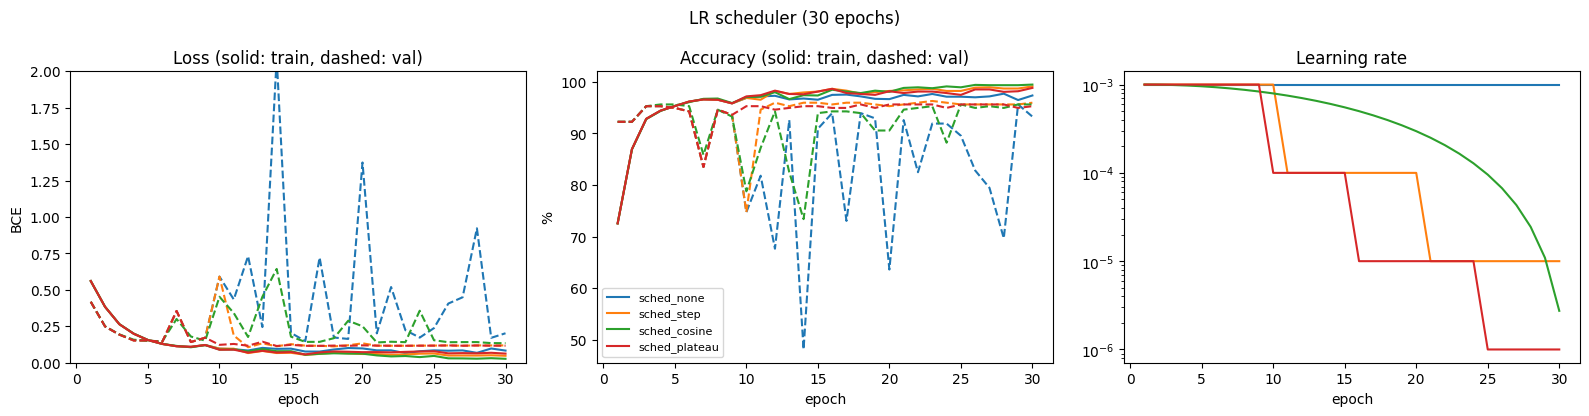

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
sched_none,29,97.36,95.62,4.09,0.1710,84.62,92.05,72.22,92.92,4203137,3.96
sched_step,23,99.12,96.30,3.16,0.1167,82.21,96.67,58.12,91.17,4203137,4.16
sched_cosine,30,99.47,95.62,3.85,0.1343,81.09,96.92,54.70,90.90,4203137,4.88
sched_plateau,23,98.83,95.62,3.54,0.1163,81.25,96.67,55.56,91.10,4203137,6.52


In [11]:
SCH = ['none', 'step', 'cosine', 'plateau']
for sc in SCH: run(f'sched_{sc}', sched=sc, epochs=30)
plot_runs([f'sched_{sc}' for sc in SCH], 'LR scheduler (30 epochs)', 's3_sched.png')
display(table([f'sched_{sc}' for sc in SCH]))

### 3.2 Number of epochs (no scheduler, so that only the training length changes)

[ep_5] best ep 4 | val acc 95.29 | test acc 82.21 auc 92.07 | 3.9s/ep
[ep_10] best ep 4 | val acc 95.29 | test acc 82.21 auc 92.07 | 4.0s/ep
[ep_60] best ep 53 | val acc 95.62 | test acc 81.25 auc 89.15 | 4.0s/ep


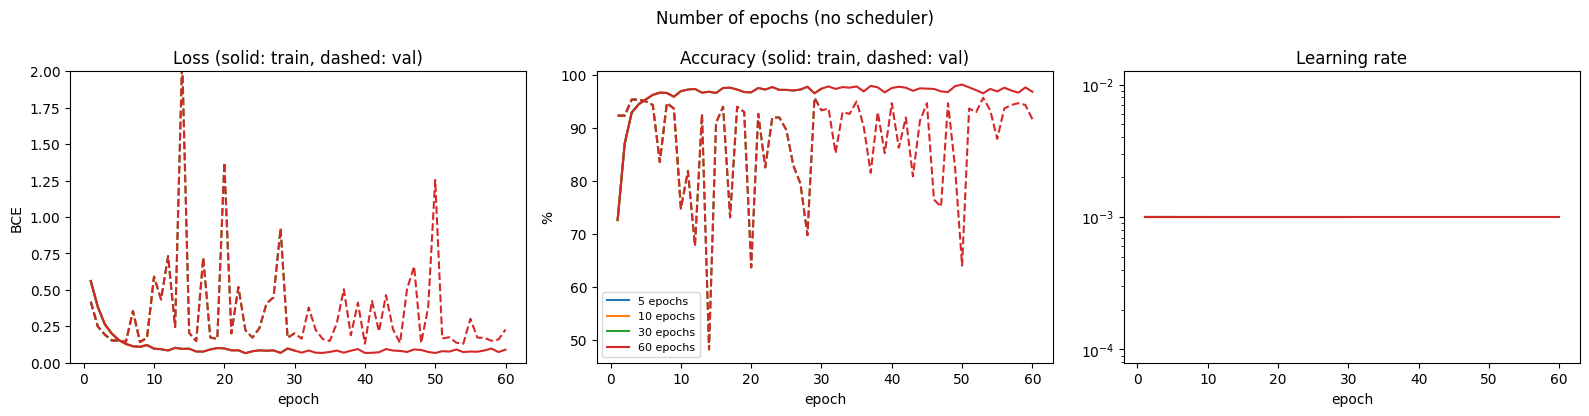

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
ep_5,4,95.30,95.29,0.35,0.1528,82.21,96.15,58.97,92.07,4203137,3.92
ep_10,4,96.89,95.29,22.14,0.1528,82.21,96.15,58.97,92.07,4203137,3.96
sched_none,29,97.36,95.62,4.09,0.1710,84.62,92.05,72.22,92.92,4203137,3.96
ep_60,53,96.77,95.62,5.19,0.1375,81.25,96.67,55.56,89.15,4203137,3.98


In [12]:
EPS = [5, 10, 30, 60]
for e in EPS:
    if e != 30: run(f'ep_{e}', sched='none', epochs=e)
EP_RUNS = [f'ep_{e}' if e != 30 else 'sched_none' for e in EPS]
plot_runs(EP_RUNS, 'Number of epochs (no scheduler)', 's3_epochs.png', labels=[f'{e} epochs' for e in EPS])
display(table(EP_RUNS))

### 3.3 Weight decay (Adam = L2 penalty added to the gradient; 30 epochs, cosine schedule)

[wd_0] best ep 17 | val acc 96.63 | test acc 84.46 auc 92.81 | 4.5s/ep
[wd_0.0001] best ep 18 | val acc 96.30 | test acc 81.41 auc 90.75 | 5.6s/ep
[wd_0.001] best ep 30 | val acc 95.62 | test acc 81.09 auc 90.90 | 8.8s/ep
[wd_0.01] best ep 29 | val acc 96.30 | test acc 79.65 auc 89.50 | 4.0s/ep
[wd_0.1] best ep 30 | val acc 96.30 | test acc 80.93 auc 90.69 | 3.1s/ep


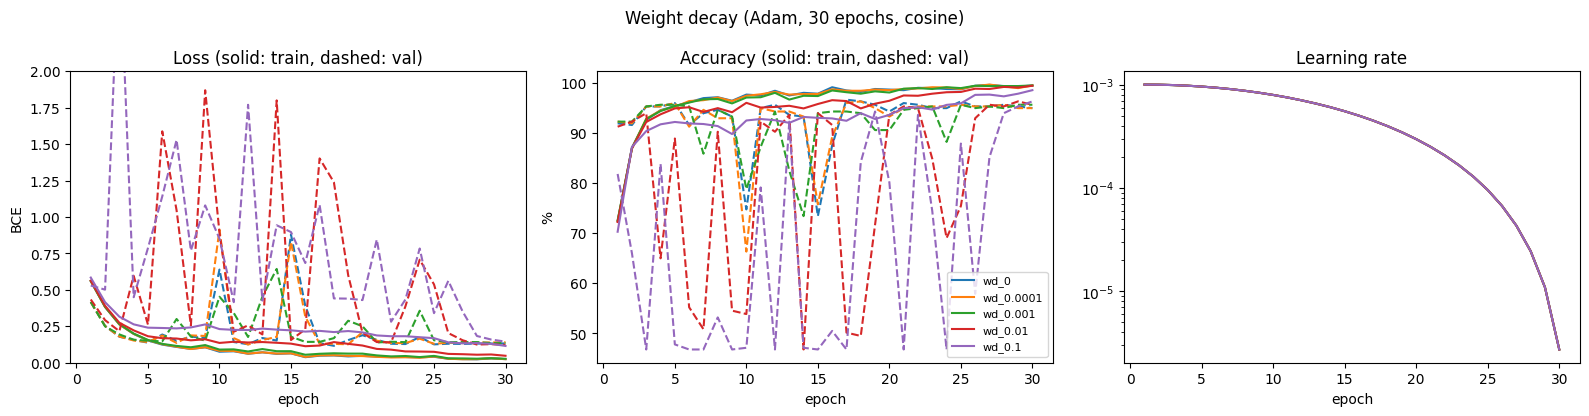

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
wd_0,17,99.47,96.63,4.52,0.1344,84.46,92.82,70.51,92.81,4203137,4.48
wd_0.0001,18,99.47,96.30,4.52,0.1297,81.41,91.03,65.38,90.75,4203137,5.61
wd_0.001,30,99.47,95.62,3.85,0.1343,81.09,96.92,54.70,90.90,4203137,8.83
wd_0.01,29,99.41,96.30,3.79,0.1274,79.65,98.46,48.29,89.50,4203137,3.96
wd_0.1,30,98.53,96.30,2.24,0.1448,80.93,97.69,52.99,90.69,4203137,3.07


In [13]:
WDS = [0, 1e-4, 1e-3, 1e-2, 1e-1]
for wd in WDS: run(f'wd_{wd:g}', wd=wd, epochs=30, sched='cosine')
plot_runs([f'wd_{wd:g}' for wd in WDS], 'Weight decay (Adam, 30 epochs, cosine)', 's3_wd.png')
display(table([f'wd_{wd:g}' for wd in WDS]))

## 4. Model Architecture
Adam lr 1e-3, wd 1e-3, batch 64, cosine schedule, val-split, seed 0. MLPs: 20 epochs; CNNs: 20 epochs.

[mlp_d1_w64] best ep 6 | val acc 95.96 | test acc 82.69 auc 92.30 | 3.3s/ep
[mlp_d3_w64] best ep 19 | val acc 95.96 | test acc 82.05 auc 91.50 | 3.4s/ep
[mlp_d5_w64] best ep 19 | val acc 95.96 | test acc 82.53 auc 92.16 | 3.2s/ep
[mlp_d3_w256] best ep 20 | val acc 96.30 | test acc 79.49 auc 91.64 | 6.5s/ep
[mlp_d3_w64_nodrop] best ep 19 | val acc 96.30 | test acc 81.89 auc 88.78 | 2.4s/ep
[mlp_d3_w64_nobn] best ep 18 | val acc 95.29 | test acc 82.69 auc 86.09 | 3.9s/ep
[cnn] best ep 20 | val acc 98.32 | test acc 81.09 auc 94.15 | 31.6s/ep
[cnn_nodrop] best ep 20 | val acc 97.98 | test acc 80.45 auc 94.36 | 33.6s/ep
[cnn_nobn] best ep 16 | val acc 91.58 | test acc 85.26 auc 92.09 | 25.6s/ep
[cnn_narrow] best ep 18 | val acc 97.98 | test acc 80.29 auc 93.73 | 17.9s/ep


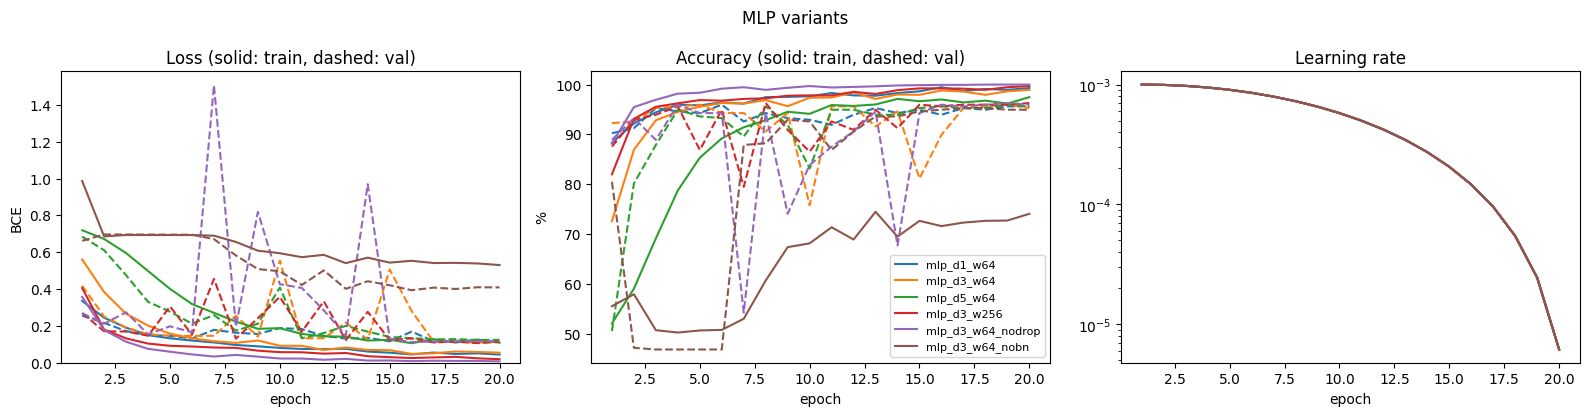

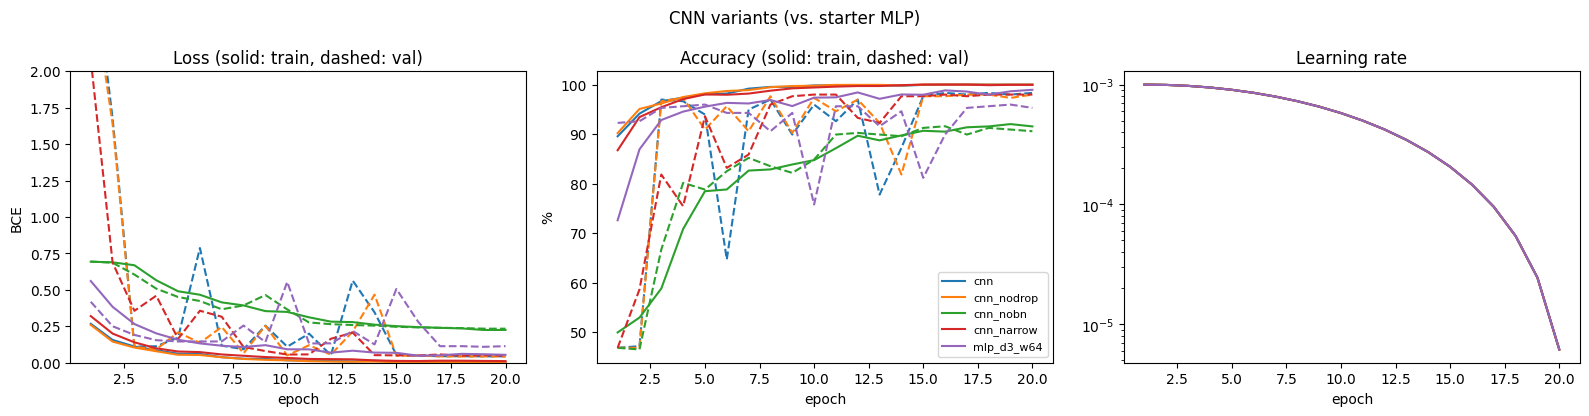

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
mlp_d1_w64,6,99.30,95.96,3.67,0.1318,82.69,94.10,63.68,92.30,4194561,3.34
mlp_d3_w64,19,98.94,95.96,3.66,0.1092,82.05,97.18,56.84,91.50,4203137,3.45
mlp_d5_w64,19,97.48,95.96,1.85,0.1230,82.53,94.62,62.39,92.16,4211713,3.25
mlp_d3_w256,20,99.71,96.30,3.41,0.1132,79.49,97.44,49.57,91.64,16910849,6.48
mlp_d3_w64_nodrop,19,100.00,96.30,4.04,0.1165,81.89,96.92,56.84,88.78,4203137,2.44
mlp_d3_w64_nobn,18,74.05,95.29,-20.90,0.4005,82.69,91.54,67.95,86.09,4202753,3.89
cnn,20,100.00,98.32,1.68,0.0439,81.09,98.97,51.28,94.15,245489,31.55
cnn_nodrop,20,100.00,97.98,2.02,0.0427,80.45,98.72,50.00,94.36,245489,33.64
cnn_nobn,16,91.54,91.58,0.97,0.2425,85.26,87.69,81.20,92.09,245121,25.62


In [14]:
ARCHS = {
    'mlp_d1_w64':     dict(arch_kw=dict(depth=1)),
    'mlp_d3_w64':     dict(arch_kw=dict()),                                  # starter
    'mlp_d5_w64':     dict(arch_kw=dict(depth=5)),
    'mlp_d3_w256':    dict(arch_kw=dict(width=256)),
    'mlp_d3_w64_nodrop': dict(arch_kw=dict(dropout=0.0)),
    'mlp_d3_w64_nobn':   dict(arch_kw=dict(bn=False)),
    'cnn':            dict(arch='cnn'),
    'cnn_nodrop':     dict(arch='cnn', arch_kw=dict(dropout=0.0)),
    'cnn_nobn':       dict(arch='cnn', arch_kw=dict(bn=False)),
    'cnn_narrow':     dict(arch='cnn', arch_kw=dict(ch=(8, 16, 32, 64, 64))),
}
for n, kw in ARCHS.items(): run(n, epochs=20, sched='cosine', **kw)
plot_runs([n for n in ARCHS if n.startswith('mlp')], 'MLP variants', 's4_mlp.png')
plot_runs([n for n in ARCHS if n.startswith('cnn')] + ['mlp_d3_w64'], 'CNN variants (vs. starter MLP)', 's4_cnn.png')
display(table(list(ARCHS)))

## 5. Data Augmentation
Model: `cnn` (Section 4), Adam lr 1e-3, wd 1e-3, cosine, 20 epochs, batch 64, val-split, seed 0.
Augmentations operate on the `uint8` 256×256 image and are applied to the training set only.
The last policy (`aug_vflip_rot90`) is a deliberately *anatomically implausible* control.

[aug_none] best ep 20 | val acc 98.32 | test acc 81.09 auc 94.15 | 43.8s/ep
[aug_hflip] best ep 20 | val acc 98.65 | test acc 80.29 auc 93.48 | 51.2s/ep
[aug_rot10] best ep 20 | val acc 97.98 | test acc 83.81 auc 94.72 | 46.0s/ep
[aug_affine] best ep 17 | val acc 98.32 | test acc 85.10 auc 95.49 | 78.0s/ep
[aug_crop] best ep 16 | val acc 97.64 | test acc 84.94 auc 95.87 | 39.6s/ep
[aug_bc] best ep 16 | val acc 97.98 | test acc 80.77 auc 94.62 | 46.5s/ep
[aug_medical] best ep 20 | val acc 98.32 | test acc 88.94 auc 96.35 | 53.3s/ep
[aug_autoaug] best ep 6 | val acc 97.98 | test acc 82.37 auc 93.42 | 35.2s/ep
[aug_randaug] best ep 18 | val acc 98.65 | test acc 83.49 auc 95.59 | 35.1s/ep
[aug_trivial] best ep 16 | val acc 98.65 | test acc 82.69 auc 95.63 | 25.2s/ep
[aug_vflip_rot90] best ep 20 | val acc 96.63 | test acc 81.57 auc 94.39 | 21.1s/ep


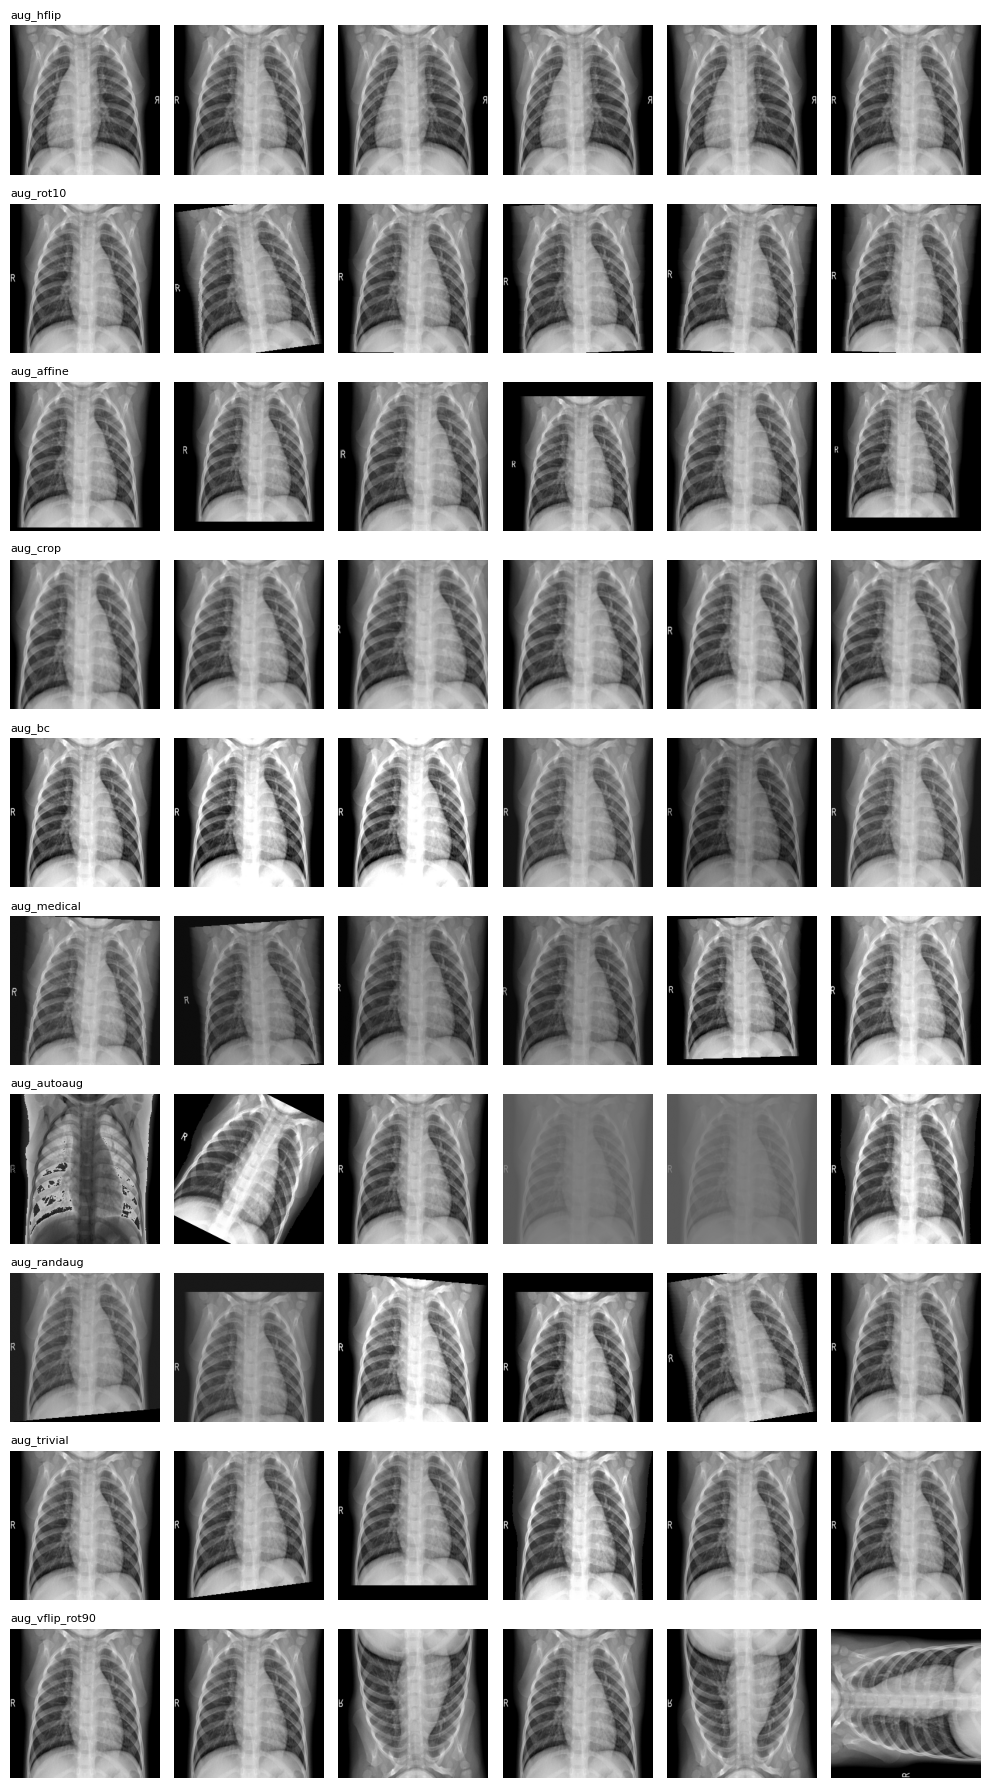

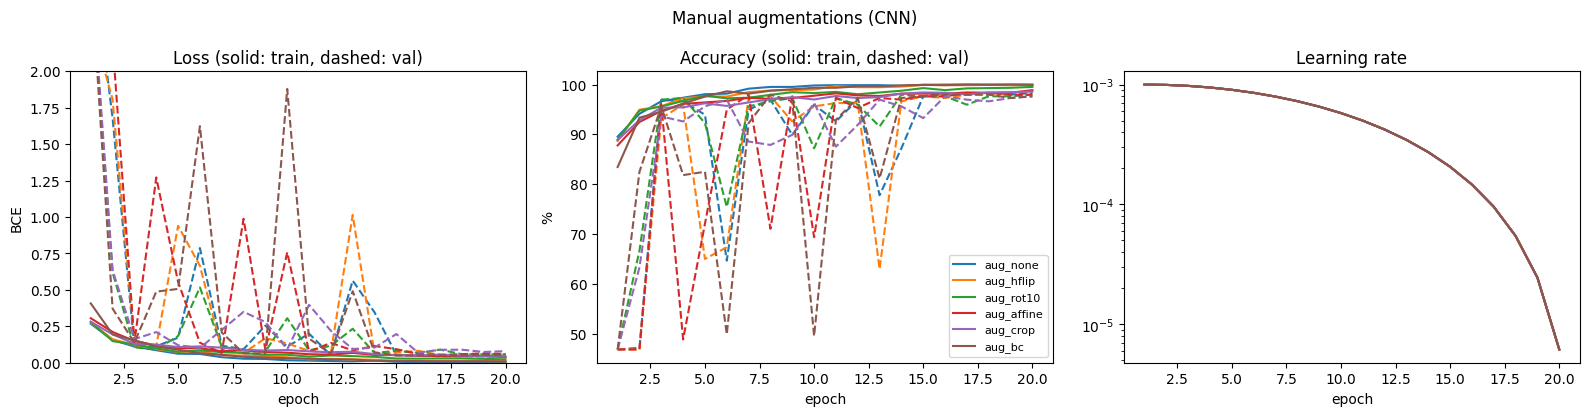

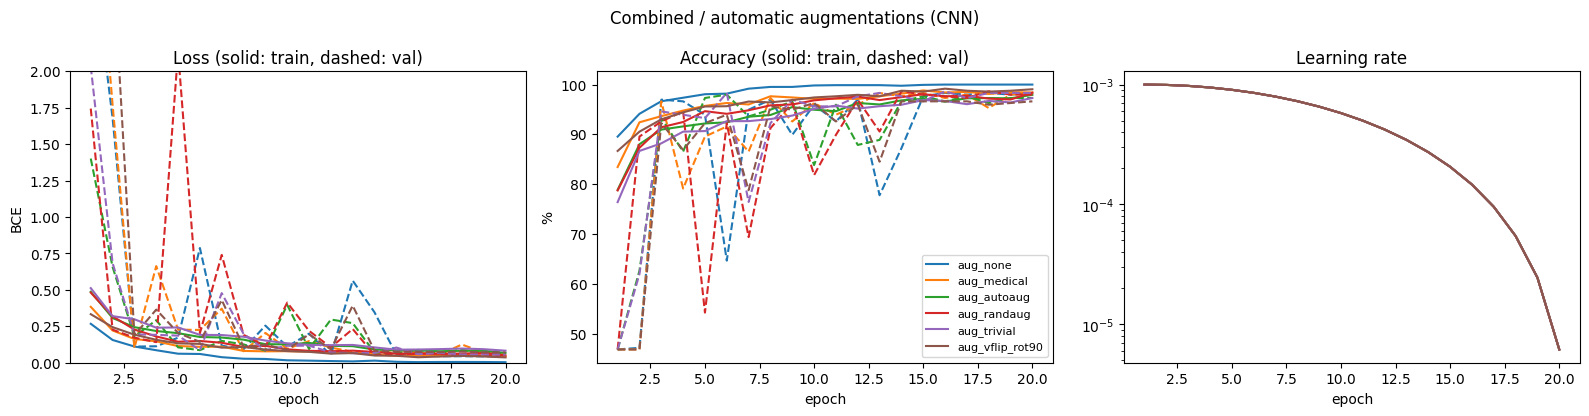

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
aug_none,20,100.00,98.32,1.68,0.0439,81.09,98.97,51.28,94.15,245489,43.77
aug_hflip,20,99.88,98.65,1.23,0.0514,80.29,98.97,49.15,93.48,245489,51.18
aug_rot10,20,99.53,97.98,1.55,0.0574,83.81,98.72,58.97,94.72,245489,45.96
aug_affine,17,98.88,98.32,0.90,0.0541,85.10,98.21,63.25,95.49,245489,78.04
aug_crop,16,98.59,97.64,0.95,0.0684,84.94,99.23,61.11,95.87,245489,39.58
aug_bc,16,99.94,97.98,2.30,0.0501,80.77,98.72,50.85,94.62,245489,46.50
aug_medical,20,98.41,98.32,0.10,0.0651,88.94,97.95,73.93,96.35,245489,53.27
aug_autoaug,6,97.94,97.98,0.64,0.0861,82.37,97.69,56.84,93.42,245489,35.19
aug_randaug,18,98.36,98.65,0.38,0.0479,83.49,98.46,58.55,95.59,245489,35.05


In [15]:
AUGS = {
    'aug_none':      None,
    'aug_hflip':     v2.RandomHorizontalFlip(),
    'aug_rot10':     v2.RandomRotation(10),
    'aug_affine':    v2.RandomAffine(degrees=0, translate=(0.06, 0.06), scale=(0.9, 1.1)),
    'aug_crop':      v2.RandomResizedCrop(256, scale=(0.75, 1.0), ratio=(0.9, 1.1), antialias=True),
    'aug_bc':        v2.ColorJitter(brightness=0.3, contrast=0.3),
    'aug_medical':   v2.Compose([v2.RandomAffine(degrees=7, translate=(0.05, 0.05), scale=(0.92, 1.08)),
                                 v2.ColorJitter(brightness=0.2, contrast=0.2)]),
    'aug_autoaug':   v2.AutoAugment(v2.AutoAugmentPolicy.IMAGENET),
    'aug_randaug':   v2.RandAugment(num_ops=2, magnitude=9),
    'aug_trivial':   v2.TrivialAugmentWide(),
    'aug_vflip_rot90': v2.Compose([v2.RandomVerticalFlip(), v2.RandomChoice([v2.RandomRotation((90, 90)), v2.Identity()])]),
}
for n, tf in AUGS.items():
    run(n, aug_tf=tf, arch='cnn', epochs=20, sched='cosine', aug=n)

fig, ax = plt.subplots(len(AUGS) - 1, 6, figsize=(10, 1.8 * (len(AUGS) - 1)))
torch.manual_seed(0)
img = data['train']['x'][np.where(ytr == 1)[0][3]]
for r, (n, tf) in enumerate(list(AUGS.items())[1:]):
    for j in range(6):
        ax[r, j].imshow(tf(img)[0], cmap='gray', vmin=0, vmax=255); ax[r, j].axis('off')
    ax[r, 0].set_title(n, fontsize=8, loc='left')
fig.tight_layout(); fig.savefig(FIG_DIR / 's5_aug_examples.png', dpi=110); plt.show()

plot_runs(['aug_none', 'aug_hflip', 'aug_rot10', 'aug_affine', 'aug_crop', 'aug_bc'], 'Manual augmentations (CNN)', 's5_manual.png')
plot_runs(['aug_none', 'aug_medical', 'aug_autoaug', 'aug_randaug', 'aug_trivial', 'aug_vflip_rot90'],
          'Combined / automatic augmentations (CNN)', 's5_auto.png')
display(table(list(AUGS)))

## 6. Conclusion
### 6.1 Final model
The final configuration is picked **only from validation-split accuracy** (ties → lower val loss) over all
experiments of Sections 2–5; the test set is not used for the choice. It is then re-trained for 30 epochs with 3 seeds.

In [16]:
all_runs = sorted(p.stem for p in RES_DIR.glob('*.json') if not p.stem.startswith(('final', 'baseline_val16')))
summary = table(all_runs).sort_values(['val_acc', 'val_loss'], ascending=[False, True])
best_name = summary.index[0]
best_cfg = json.loads((RES_DIR / f'{best_name}.json').read_text())['cfg']
print('selected:', best_name, best_cfg)
display(summary.head(10))

selected: aug_randaug {'arch': 'cnn', 'arch_kw': {}, 'opt': 'adam', 'lr': 0.001, 'wd': 0.001, 'bs': 64, 'epochs': 20, 'sched': 'cosine', 'aug': 'aug_randaug', 'val': 'split', 'seed': 0}


,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
aug_randaug,18,98.36,98.65,0.38,0.0479,83.49,98.46,58.55,95.59,245489,35.05
aug_hflip,20,99.88,98.65,1.23,0.0514,80.29,98.97,49.15,93.48,245489,51.18
aug_trivial,16,97.30,98.65,-1.02,0.0585,82.69,98.97,55.56,95.63,245489,25.23
aug_none,20,100.00,98.32,1.68,0.0439,81.09,98.97,51.28,94.15,245489,43.77
cnn,20,100.00,98.32,1.68,0.0439,81.09,98.97,51.28,94.15,245489,31.55
aug_affine,17,98.88,98.32,0.90,0.0541,85.10,98.21,63.25,95.49,245489,78.04
aug_medical,20,98.41,98.32,0.10,0.0651,88.94,97.95,73.93,96.35,245489,53.27
cnn_nodrop,20,100.00,97.98,2.02,0.0427,80.45,98.72,50.00,94.36,245489,33.64
cnn_narrow,18,99.94,97.98,1.96,0.0493,80.29,98.46,50.00,93.73,61689,17.91


Epoch 1/30 - loss: 0.4814 - train_acc: 78.74% - val_loss: 1.7443 - val_acc: 46.80% - time: 88.1s
Epoch 2/30 - loss: 0.3187 - train_acc: 87.38% - val_loss: 0.2382 - val_acc: 89.23% - time: 113.8s
Epoch 3/30 - loss: 0.2278 - train_acc: 91.43% - val_loss: 0.1903 - val_acc: 91.58% - time: 121.2s
Epoch 4/30 - loss: 0.1799 - train_acc: 92.60% - val_loss: 0.1433 - val_acc: 94.61% - time: 118.5s
Epoch 5/30 - loss: 0.1463 - train_acc: 94.54% - val_loss: 3.0695 - val_acc: 53.87% - time: 104.2s
Epoch 6/30 - loss: 0.1487 - train_acc: 94.19% - val_loss: 0.3419 - val_acc: 84.85% - time: 119.5s
Epoch 7/30 - loss: 0.1441 - train_acc: 94.60% - val_loss: 0.8768 - val_acc: 63.30% - time: 112.3s
Epoch 8/30 - loss: 0.1095 - train_acc: 96.07% - val_loss: 0.2523 - val_acc: 89.23% - time: 125.0s
Epoch 9/30 - loss: 0.1233 - train_acc: 95.71% - val_loss: 0.1312 - val_acc: 94.28% - time: 89.7s
Epoch 10/30 - loss: 0.0994 - train_acc: 96.71% - val_loss: 0.4266 - val_acc: 81.82% - time: 89.6s
Epoch 11/30 - loss: 0.

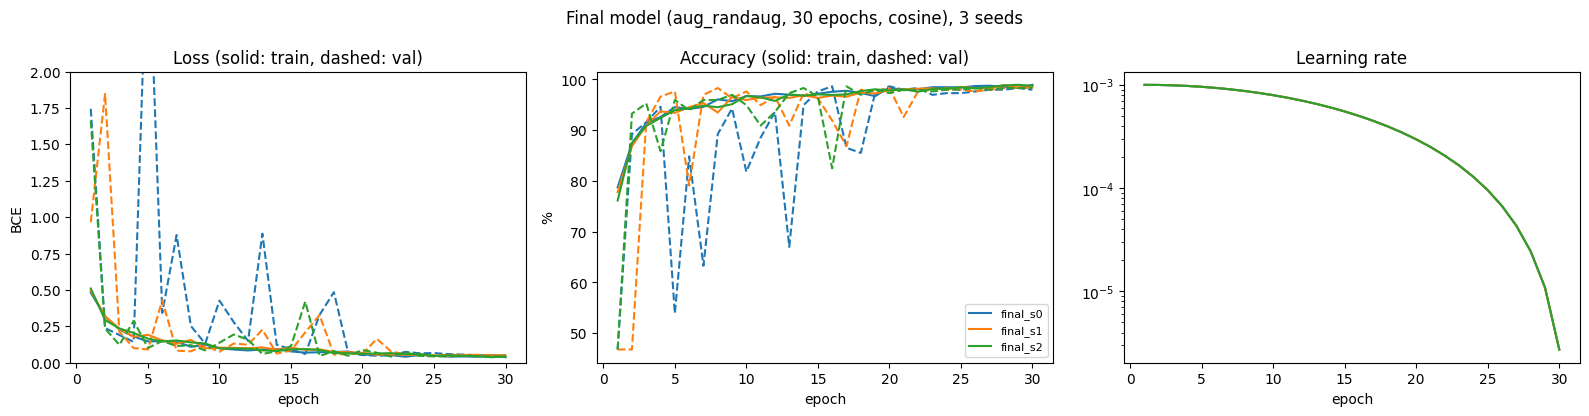

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
final_s0,20,98.94,98.65,0.96,0.0530,83.17,98.72,57.26,95.58,245489,97.44
final_s1,30,98.47,98.32,0.16,0.0523,83.81,98.97,58.55,95.54,245489,97.50
final_s2,17,98.77,98.65,0.45,0.0461,87.98,97.95,71.37,96.25,245489,95.46


final test (mean ± std over 3 seeds):
      val_acc  test_acc  test_sens  test_spec  test_auc
mean    98.54     84.99      98.55      62.39     95.79
std      0.19      2.61       0.53       7.80      0.40
baseline test (mean ± std over 3 seeds):
      val_acc  test_acc  test_sens  test_spec  test_auc
mean    95.40     80.50      94.19      57.69     90.15
std      0.19      3.13       3.21      13.33      1.45


In [17]:
final_names = []
for s in range(3):
    n = f'final_s{s}'
    run(n, aug_tf=AUGS.get(best_cfg['aug']), **{**best_cfg, 'epochs': 30, 'sched': 'cosine', 'seed': s},
        verbose=(s == 0))
    final_names.append(n)
plot_runs(final_names, f'Final model ({best_name}, 30 epochs, cosine), 3 seeds', 's6_final.png')
ft = table(final_names)
display(ft)
print('final test (mean ± std over 3 seeds):')
print(ft[['val_acc', 'test_acc', 'test_sens', 'test_spec', 'test_auc']].agg(['mean', 'std']).round(2))
base = table([f'baseline_s{s}' for s in range(3)])
print('baseline test (mean ± std over 3 seeds):')
print(base[['val_acc', 'test_acc', 'test_sens', 'test_spec', 'test_auc']].agg(['mean', 'std']).round(2))

### 6.2 Final model — confusion matrix and decision threshold
The training data are balanced (50/50) but the test set is 62.5 % PNEUMONIA, so the 0.5 threshold is not
guaranteed to be the best operating point. The threshold that maximizes **val-split** accuracy is reported for comparison.

threshold 0.5: {'loss': 0.5008176969050987, 'acc': 83.17307692307693, 'sens': 98.71794871794872, 'spec': 57.26495726495727, 'f1': 88.0, 'auc': 95.57801884724961, 'cm': [[134, 100], [5, 385]]}
threshold 0.42 (chosen on val-split): {'loss': 0.5008176969050987, 'acc': 82.6923076923077, 'sens': 98.97435897435898, 'spec': 55.55555555555556, 'f1': 87.72727272727273, 'auc': 95.57801884724961, 'cm': [[130, 104], [4, 386]]}


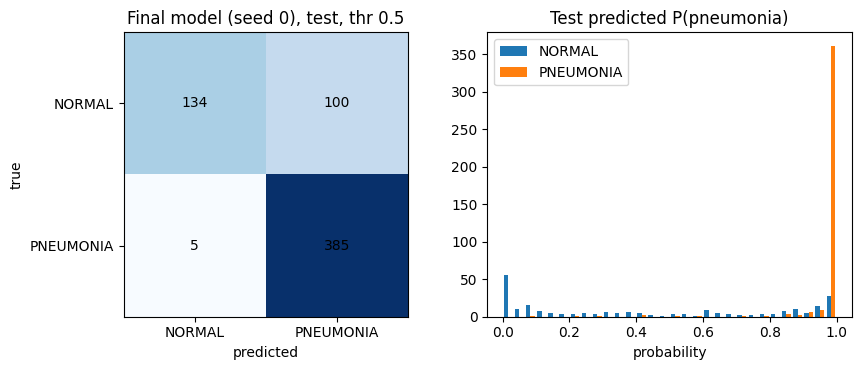

In [18]:
model = ARCH[best_cfg['arch']](**best_cfg['arch_kw']).to(device)
model.load_state_dict(torch.load(CKPT_DIR / 'final_s0.pth'))
pt, yt = predict(model, test_ds)
_, va = make_sets('split')
pv, yv = predict(model, va)
ths = np.linspace(0.05, 0.95, 91)
thr_val = ths[np.argmax([metrics(pv, yv, t)['acc'] for t in ths])]
m05, mval = metrics(pt, yt), metrics(pt, yt, thr_val)
print(f'threshold 0.5: {m05}\nthreshold {thr_val:.2f} (chosen on val-split): {mval}')
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
ax[0].imshow(m05['cm'], cmap='Blues')
for i in range(2):
    for j in range(2): ax[0].text(j, i, m05['cm'][i][j], ha='center', va='center')
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASSES, yticklabels=CLASSES, xlabel='predicted', ylabel='true',
          title='Final model (seed 0), test, thr 0.5')
ax[1].hist([pt[yt == 0], pt[yt == 1]], bins=30, label=CLASSES, stacked=False)
ax[1].set(title='Test predicted P(pneumonia)', xlabel='probability'); ax[1].legend()
fig.tight_layout(); fig.savefig(FIG_DIR / 's6_cm.png', dpi=130); plt.show()

### 6.3 Summary of all experiments

In [19]:
pd.set_option('display.max_rows', 100)
display(table(['baseline_val16'] + all_runs + final_names))

,best_ep,train_acc,val_acc,gap,val_loss,test_acc,test_sens,test_spec,test_auc,params,s_per_ep
run,,,,,,,,,,,
baseline_val16,10,97.35,93.75,3.60,0.1965,81.89,96.67,57.26,92.19,4203137,5.04
aug_affine,17,98.88,98.32,0.90,0.0541,85.10,98.21,63.25,95.49,245489,78.04
aug_autoaug,6,97.94,97.98,0.64,0.0861,82.37,97.69,56.84,93.42,245489,35.19
aug_bc,16,99.94,97.98,2.30,0.0501,80.77,98.72,50.85,94.62,245489,46.50
aug_crop,16,98.59,97.64,0.95,0.0684,84.94,99.23,61.11,95.87,245489,39.58
aug_hflip,20,99.88,98.65,1.23,0.0514,80.29,98.97,49.15,93.48,245489,51.18
aug_medical,20,98.41,98.32,0.10,0.0651,88.94,97.95,73.93,96.35,245489,53.27
aug_none,20,100.00,98.32,1.68,0.0439,81.09,98.97,51.28,94.15,245489,43.77
aug_randaug,18,98.36,98.65,0.38,0.0479,83.49,98.46,58.55,95.59,245489,35.05
